In [173]:
import numpy as np
import pandas as pd
import jax
import jax.numpy as jnp
import optax
import matplotlib.pyplot as plt

LAT_REF, LON_REF = 6.2442, -75.5812
csv_path = '../data/Estaciones_PM2.5_2026_06.csv'

DEFAULT_STATIONS = {
    'SAB-RAME': (6.145500, -75.621260),
    'MED-VILL': (6.261722, -75.551639),
    'MED-SCRI': (6.280500, -75.636600),
    'MED-ARAN': (6.293460, -75.556427),
    'BEL-FEVE': (6.337550, -75.567800),
    'MED-FISC': (6.268789, -75.573708),
    'CEN-TRAF': (6.252561, -75.56958),
    'EST-HOSP': (6.155531, -75.644169),
    'EST-TABL': (6.118056, -75.631943),
    'MED-BEME': (6.243, -75.61201),
    'MED-SELE': (6.236361, -75.498472),
    'MED-PROV': (6.229778, -75.586052),
    'MED-ALTA': (6.221894, -75.610603),
    'MED-CES':  (6.207386, -75.551851),
    'MED-TESO': (6.199870, -75.560950),
    'ITA-CJUS': (6.185667, -75.597206),
}

df = pd.read_csv(csv_path, parse_dates=['fecha_hora'], index_col='fecha_hora')
codes = list(DEFAULT_STATIONS.keys())
valid_codes = [c for c in codes if c in df.columns]

df_clean = df[valid_codes].ffill().bfill()
total_steps = len(df_clean)

Y_raw = jnp.array(df_clean.iloc[:total_steps].values[:, 0])
dt = 1.0 / 24.0
t_axis = np.arange(total_steps) * dt

def transform_data(y):
    return jnp.log(y + 1.0)

Y_obs = transform_data(Y_raw)

In [201]:
LAG_STEPS = 24*7  # Número de horas hacia atrás que recordará el modelo

def create_lags(y_seq, lag):
    y_prevs = []
    y_currs = []
    for i in range(lag, len(y_seq)):
        # Historial cronológico: [x_{t-3}, x_{t-2}, x_{t-1}]
        y_prevs.append(y_seq[i-lag:i])
        y_currs.append(y_seq[i])
    return jnp.array(y_prevs), jnp.array(y_currs)

X_lags, Y_target = create_lags(Y_obs, LAG_STEPS)

# División 70% Train, 30% Test
train_size = int(len(X_lags) * 0.8)
X_train, X_test = X_lags[:train_size], X_lags[train_size:]
Y_train, Y_test = Y_target[:train_size], Y_target[train_size:]

t_train = t_axis[LAG_STEPS : LAG_STEPS + train_size]
t_test = t_axis[LAG_STEPS + train_size :]

print(f"Muestras de entrenamiento: {len(X_train)} | Muestras de test: {len(X_test)}")

Muestras de entrenamiento: 441 | Muestras de test: 111


In [202]:
key = jax.random.PRNGKey(42)
k1, k2 = jax.random.split(key, 2)

params = {
    'lmbda': jnp.array(1.0),
    'mu_w': jax.random.normal(k1, (LAG_STEPS,)) * 0.1,  # Un peso por cada hora de memoria
    'mu_b': jnp.array(0.0),
    'sig_w': jax.random.normal(k2, (1,)) * 0.1,
    'sig_b': jnp.array(0.0)
}

def compute_mu(p, x_seq_prev):
    # Multiplica el historial por los pesos de cada retardo
    return jnp.dot(x_seq_prev, p['mu_w']) + p['mu_b']

def compute_sigma(p, x_seq_prev):
    # La volatilidad evalúa el valor más reciente del historial (el último)
    last_val = x_seq_prev[..., -1]
    return jax.nn.softplus(last_val * p['sig_w'] + p['sig_b']) + 1e-3

def transition_moments(x_last, mu_val, sigma_val, lmbda, dt):
    lmbda_pos = jnp.maximum(lmbda, 1e-4)
    exp_term = jnp.exp(-lmbda_pos * dt)
    
    m_t = x_last * exp_term + mu_val * (1.0 - exp_term)
    v_t = (sigma_val**2 / (2.0 * lmbda_pos)) * (1.0 - jnp.exp(-2.0 * lmbda_pos * dt))
    
    return m_t, jnp.maximum(v_t, 1e-5)

def loss_fn(p, x_seqs, y_curr, dt):
    x_last = x_seqs[:, -1] # El valor en t-1
    
    mu_t = compute_mu(p, x_seqs)
    sigma_t = compute_sigma(p, x_seqs)
    m_t, v_t = transition_moments(x_last, mu_t, sigma_t, p['lmbda'], dt)
    
    nll = 0.5 * jnp.sum(jnp.log(2.0 * jnp.pi * v_t) + ((y_curr - m_t)**2) / v_t)
    return nll

In [203]:
optimizer = optax.adam(learning_rate=0.001)
opt_state = optimizer.init(params)

@jax.jit
def step(p, opt_st, x_s, y_c, dt):
    loss_val, grads = jax.value_and_grad(loss_fn)(p, x_s, y_c, dt)
    updates, opt_st = optimizer.update(grads, opt_st, p)
    p = optax.apply_updates(p, updates)
    return p, opt_st, loss_val

epochs = 15000
print("Iniciando entrenamiento con memoria de retardos...")
for epoch in range(epochs):
    params, opt_state, loss_val = step(params, opt_state, X_train, Y_train, dt)
    if epoch % 500 == 0:
        print(f"Época {epoch:3d} | Pérdida Train NLL: {loss_val:.4f} | Lambda: {params['lmbda']:.4f}")

print("\n¡Entrenamiento finalizado!")

Iniciando entrenamiento con memoria de retardos...
Época   0 | Pérdida Train NLL: 2864.4326 | Lambda: 0.9990
Época 500 | Pérdida Train NLL: 741.0502 | Lambda: 1.5583
Época 1000 | Pérdida Train NLL: 443.7654 | Lambda: 1.9955
Época 1500 | Pérdida Train NLL: 350.0241 | Lambda: 2.3205
Época 2000 | Pérdida Train NLL: 311.0649 | Lambda: 2.5777
Época 2500 | Pérdida Train NLL: 290.4418 | Lambda: 2.7968
Época 3000 | Pérdida Train NLL: 276.4756 | Lambda: 3.0029
Época 3500 | Pérdida Train NLL: 265.6998 | Lambda: 3.2071
Época 4000 | Pérdida Train NLL: 257.6989 | Lambda: 3.4011
Época 4500 | Pérdida Train NLL: 252.4215 | Lambda: 3.5675
Época 5000 | Pérdida Train NLL: 249.3454 | Lambda: 3.6897
Época 5500 | Pérdida Train NLL: 247.4905 | Lambda: 3.7626
Época 6000 | Pérdida Train NLL: 246.0469 | Lambda: 3.7930
Época 6500 | Pérdida Train NLL: 244.5353 | Lambda: 3.7927
Época 7000 | Pérdida Train NLL: 242.6959 | Lambda: 3.7712
Época 7500 | Pérdida Train NLL: 240.3553 | Lambda: 3.7331
Época 8000 | Pérdida T

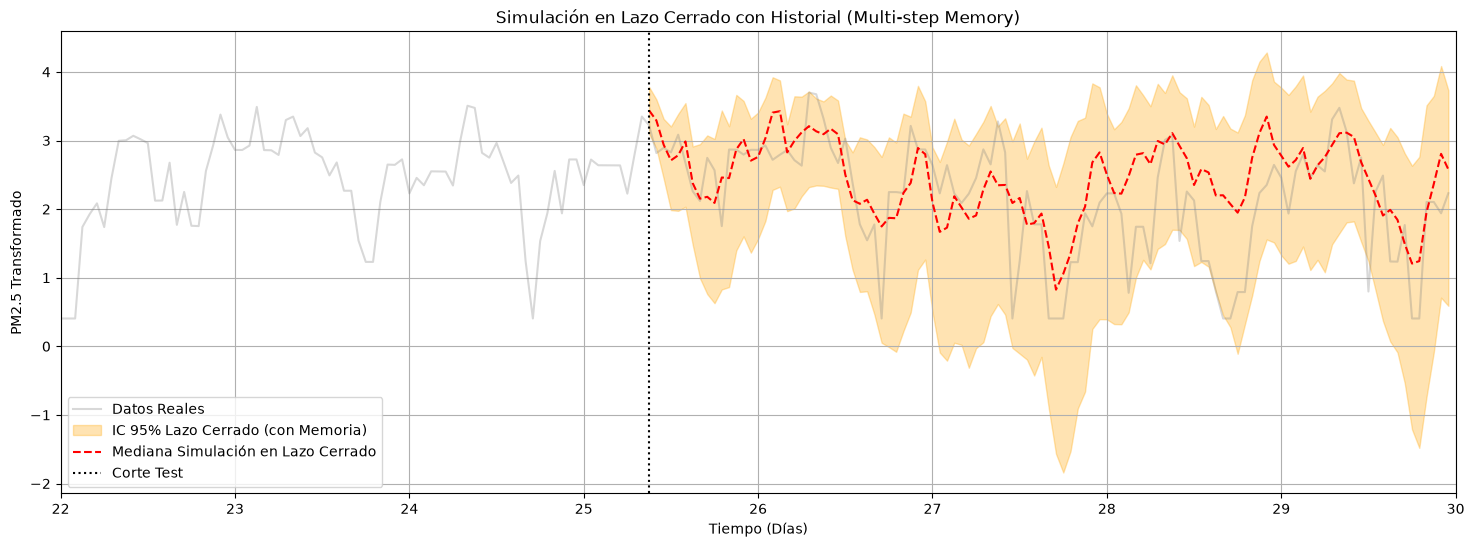

In [207]:
num_samples = 1000
test_steps = len(X_test)
sim_key = jax.random.PRNGKey(100)

simulated_paths = []
# Inicializamos el buffer con la primera ventana del conjunto de test
current_window = jnp.tile(X_test[0], (num_samples, 1))
subkeys = jax.random.split(sim_key, test_steps)

for i in range(test_steps):
    mu_val = compute_mu(params, current_window)
    sigma_val = compute_sigma(params, current_window)
    x_last = current_window[:, -1]
    
    m_t, v_t = transition_moments(x_last, mu_val, sigma_val, params['lmbda'], dt)
    
    noise = jax.random.normal(subkeys[i], (num_samples,))
    next_val = m_t + jnp.sqrt(v_t) * noise
    simulated_paths.append(next_val)
    
    # Actualizamos el buffer deslizante de memoria (desplaza los elementos y añade el nuevo)
    current_window = jnp.concatenate([current_window[:, 1:], next_val[:, None]], axis=1)

simulated_paths = jnp.stack(simulated_paths, axis=1)

median_path = jnp.median(simulated_paths, axis=0)
ci_lower = jnp.percentile(simulated_paths, 2.5, axis=0)
ci_upper = jnp.percentile(simulated_paths, 97.5, axis=0)

# Gráfica de resultados
plt.figure(figsize=(18, 6))
plt.plot(t_axis, Y_obs, label='Datos Reales', alpha=0.3, color='gray')
plt.fill_between(t_test, ci_lower, ci_upper, color='orange', alpha=0.3, label='IC 95% Lazo Cerrado (con Memoria)')
plt.plot(t_test, median_path, label='Mediana Simulación en Lazo Cerrado', color='red', linestyle='--')

plt.xlim(22,30)
plt.axvline(x=t_test[0], color='black', linestyle=':', label='Corte Test')
plt.xlabel('Tiempo (Días)')
plt.ylabel('PM2.5 Transformado')
plt.title('Simulación en Lazo Cerrado con Historial (Multi-step Memory)')
plt.legend()
plt.grid(True)
plt.show()

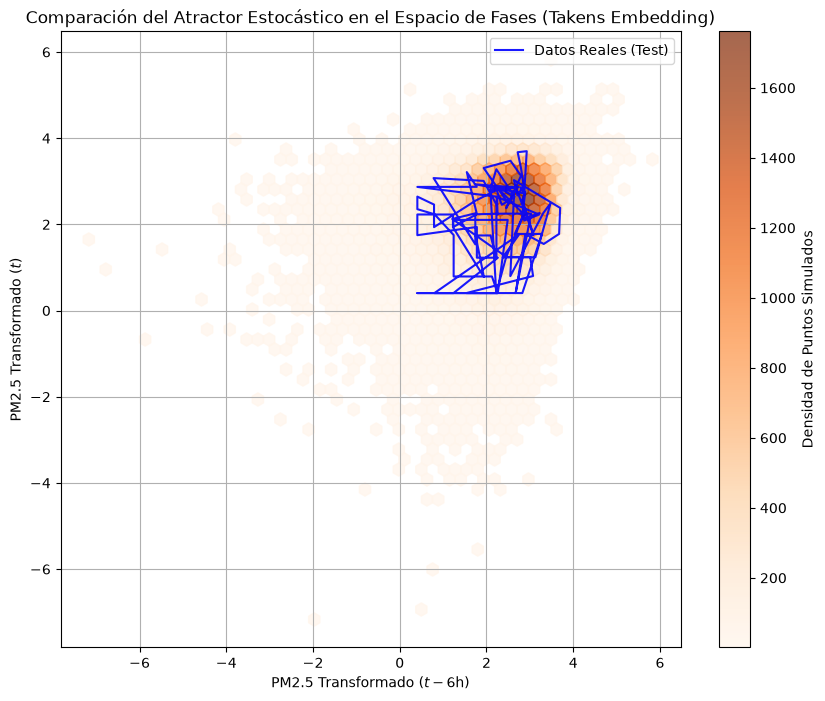

In [219]:
import matplotlib.pyplot as plt

# Definimos un retardo tau para el espacio de fases (por ejemplo, 6 horas)
tau = 6

# 1. Extraer vectores de retardo para los datos reales de Test
real_z_t = Y_test[tau:]
real_z_lag = Y_test[:-tau]

# 2. Extraer vectores de retardo para todas las simulaciones en lazo cerrado (nube estocástica)
all_sim_z_t = simulated_paths[:, tau:].flatten()
all_sim_z_lag = simulated_paths[:, :-tau].flatten()

# --- Gráfica de comparación de Retratos de Fases ---
plt.figure(figsize=(10, 8))

# Gráfico de densidad hexagonal nativo de Matplotlib
hb = plt.hexbin(all_sim_z_lag, all_sim_z_t, gridsize=50, cmap='Oranges', alpha=0.7, mincnt=1)
plt.colorbar(hb, label='Densidad de Puntos Simulados')

# Superponemos la trayectoria real de test en el espacio de fases
plt.plot(real_z_lag, real_z_t, color='blue', alpha=0.9, linewidth=1.5, label='Datos Reales (Test)')

plt.xlabel(f'PM2.5 Transformado ($t - {tau}\\text{{h}}$)')
plt.ylabel('PM2.5 Transformado ($t$)')
plt.title('Comparación del Atractor Estocástico en el Espacio de Fases (Takens Embedding)')
plt.legend()
plt.grid(True)
plt.show()

 RESULTADOS DE VALIDACIÓN CUANTITATIVA 
Distancia de Wasserstein (en z_t):      0.3143
Distancia de Wasserstein (en z_t-6): 0.2851
(Un valor cercano a 0 indica que las distribuciones son prácticamente idénticas)



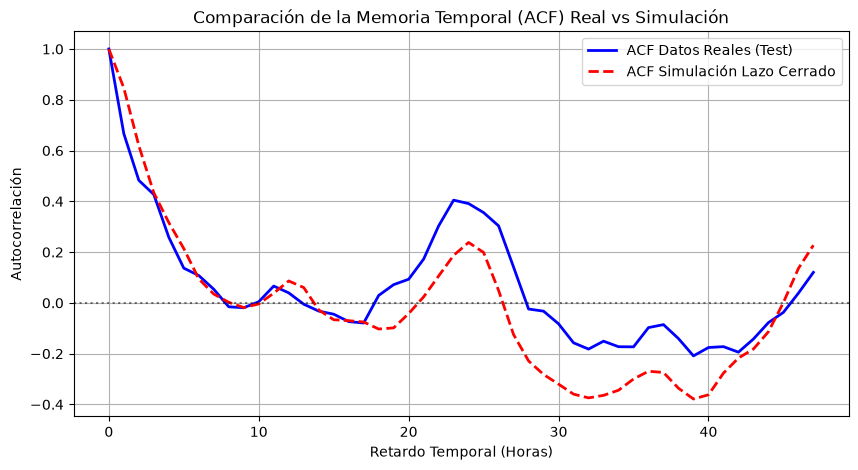

In [225]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# --- 1. Cálculo de la Función de Autocorrelación (ACF) ---
def calculate_acf(series, max_lags=48):
    series = np.asarray(series)
    n = len(series)
    mean = np.mean(series)
    c0 = np.var(series)
    acf_vals = []
    for lag in range(max_lags):
        if lag == 0:
            acf_vals.append(1.0)
        else:
            c = np.sum((series[:-lag] - mean) * (series[lag:] - mean)) / n
            acf_vals.append(c / c0)
    return np.array(acf_vals)

max_lags = 48
acf_real = calculate_acf(Y_test, max_lags)
# Usamos la mediana de la simulación en lazo cerrado para la ACF representativa
acf_sim = calculate_acf(median_path, max_lags)

# --- 2. Distancia de Wasserstein (Marginales del Espacio de Fases) ---
# Evaluamos la distancia entre las distribuciones marginales z_t y z_{t-tau}
tau = 6
w_dist_t = stats.wasserstein_distance(Y_test[tau:], median_path[tau:])
w_dist_lag = stats.wasserstein_distance(Y_test[:-tau], median_path[:-tau])

print("==========================================")
print(" RESULTADOS DE VALIDACIÓN CUANTITATIVA ")
print("==========================================")
print(f"Distancia de Wasserstein (en z_t):      {w_dist_t:.4f}")
print(f"Distancia de Wasserstein (en z_t-{tau}): {w_dist_lag:.4f}")
print("(Un valor cercano a 0 indica que las distribuciones son prácticamente idénticas)\n")

# --- 3. Gráfica Comparativa de Autocorrelaciones ---
plt.figure(figsize=(10, 5))
lags_axis = np.arange(max_lags) * dt * 24 # Convertir a horas
plt.plot(lags_axis, acf_real, label='ACF Datos Reales (Test)', color='blue', linewidth=2)
plt.plot(lags_axis, acf_sim, label='ACF Simulación Lazo Cerrado', color='red', linestyle='--', linewidth=2)
plt.axhline(0, color='black', linestyle=':', alpha=0.5)
plt.xlabel('Retardo Temporal (Horas)')
plt.ylabel('Autocorrelación')
plt.title('Comparación de la Memoria Temporal (ACF) Real vs Simulación')
plt.legend()
plt.grid(True)
plt.show()